In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split
import os
import json

In [2]:
device = torch.device("cpu")

print("Device:", device)

Device: cpu


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training dataset size:", len(train_dataset))
print("Test dataset size:", len(test_dataset))

100%|██████████| 170M/170M [00:22<00:00, 7.50MB/s]


Training dataset size: 50000
Test dataset size: 10000


In [4]:
train_size = 45000
validation_size = 5000

train_subset, validation_subset = random_split(
    train_dataset,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(validation_subset))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [5]:
batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

Training batches: 352
Validation batches: 40
Test batches: 79


In [6]:
class FlexibleCNN(nn.Module):
    def __init__(self, width=32, depth=2):
        super(FlexibleCNN, self).__init__()

        layers = []
        input_channels = 3

        for i in range(depth):
            output_channels = width * (2 ** i)

            layers.append(
                nn.Conv2d(
                    input_channels,
                    output_channels,
                    kernel_size=3,
                    padding=1
                )
            )

            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))

            input_channels = output_channels

        self.features = nn.Sequential(*layers)

        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.classifier = nn.Linear(
            input_channels * 4 * 4,
            10
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x

In [7]:
model = FlexibleCNN(width=32, depth=2).to(device)

dummy_input = torch.randn(1, 3, 32, 32)
output = model(dummy_input)

total_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model output shape:", output.shape)
print("Trainable parameters:", total_parameters)

Model output shape: torch.Size([1, 10])
Trainable parameters: 29642


In [8]:
def train_model(model, train_loader, validation_loader, epochs=10):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    train_accuracies = []
    validation_accuracies = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / total
        epoch_train_accuracy = 100 * correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_train_accuracy)

        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in validation_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        validation_accuracy = 100 * correct / total

        validation_accuracies.append(validation_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Training Accuracy: {epoch_train_accuracy:.2f}% "
            f"Validation Accuracy: {validation_accuracy:.2f}%"
        )

    return model, train_losses, train_accuracies, validation_accuracies

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Current device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Current device: cuda
GPU: Tesla T4


In [11]:
narrow_model = FlexibleCNN(width=16, depth=2)

narrow_model, narrow_train_losses, narrow_train_accuracies, narrow_validation_accuracies = train_model(
    narrow_model,
    train_loader,
    validation_loader,
    epochs=10
)

Epoch [1/10] Loss: 1.6672 Training Accuracy: 40.76% Validation Accuracy: 49.36%
Epoch [2/10] Loss: 1.3233 Training Accuracy: 53.48% Validation Accuracy: 55.22%
Epoch [3/10] Loss: 1.2052 Training Accuracy: 57.66% Validation Accuracy: 58.22%
Epoch [4/10] Loss: 1.1289 Training Accuracy: 60.56% Validation Accuracy: 60.74%
Epoch [5/10] Loss: 1.0708 Training Accuracy: 62.80% Validation Accuracy: 62.66%
Epoch [6/10] Loss: 1.0306 Training Accuracy: 64.16% Validation Accuracy: 62.82%
Epoch [7/10] Loss: 0.9935 Training Accuracy: 65.59% Validation Accuracy: 65.14%
Epoch [8/10] Loss: 0.9661 Training Accuracy: 66.54% Validation Accuracy: 64.60%
Epoch [9/10] Loss: 0.9404 Training Accuracy: 67.22% Validation Accuracy: 66.44%
Epoch [10/10] Loss: 0.9245 Training Accuracy: 68.14% Validation Accuracy: 65.56%


In [12]:
medium_model = FlexibleCNN(width=32, depth=2)

medium_model, medium_train_losses, medium_train_accuracies, medium_validation_accuracies = train_model(
    medium_model,
    train_loader,
    validation_loader,
    epochs=10
)

Epoch [1/10] Loss: 1.5205 Training Accuracy: 46.24% Validation Accuracy: 53.34%
Epoch [2/10] Loss: 1.1989 Training Accuracy: 57.90% Validation Accuracy: 59.84%
Epoch [3/10] Loss: 1.0622 Training Accuracy: 62.92% Validation Accuracy: 64.16%
Epoch [4/10] Loss: 0.9788 Training Accuracy: 66.04% Validation Accuracy: 65.34%
Epoch [5/10] Loss: 0.9236 Training Accuracy: 68.20% Validation Accuracy: 67.54%
Epoch [6/10] Loss: 0.8784 Training Accuracy: 69.79% Validation Accuracy: 66.64%
Epoch [7/10] Loss: 0.8435 Training Accuracy: 70.88% Validation Accuracy: 68.92%
Epoch [8/10] Loss: 0.8128 Training Accuracy: 72.14% Validation Accuracy: 69.40%
Epoch [9/10] Loss: 0.7909 Training Accuracy: 72.90% Validation Accuracy: 69.40%
Epoch [10/10] Loss: 0.7613 Training Accuracy: 73.89% Validation Accuracy: 70.80%


In [13]:
wide_model = FlexibleCNN(width=64, depth=2)

wide_model, wide_train_losses, wide_train_accuracies, wide_validation_accuracies = train_model(
    wide_model,
    train_loader,
    validation_loader,
    epochs=10
)

Epoch [1/10] Loss: 1.4630 Training Accuracy: 47.75% Validation Accuracy: 57.14%
Epoch [2/10] Loss: 1.1101 Training Accuracy: 61.20% Validation Accuracy: 63.40%
Epoch [3/10] Loss: 0.9676 Training Accuracy: 66.56% Validation Accuracy: 66.22%
Epoch [4/10] Loss: 0.8841 Training Accuracy: 69.38% Validation Accuracy: 68.02%
Epoch [5/10] Loss: 0.8208 Training Accuracy: 71.62% Validation Accuracy: 69.02%
Epoch [6/10] Loss: 0.7709 Training Accuracy: 73.30% Validation Accuracy: 72.08%
Epoch [7/10] Loss: 0.7339 Training Accuracy: 74.60% Validation Accuracy: 71.62%
Epoch [8/10] Loss: 0.6954 Training Accuracy: 75.98% Validation Accuracy: 72.94%
Epoch [9/10] Loss: 0.6639 Training Accuracy: 77.15% Validation Accuracy: 73.64%
Epoch [10/10] Loss: 0.6403 Training Accuracy: 77.90% Validation Accuracy: 73.04%


In [14]:
shallow_model = FlexibleCNN(width=32, depth=1)

shallow_model, shallow_train_losses, shallow_train_accuracies, shallow_validation_accuracies = train_model(
    shallow_model,
    train_loader,
    validation_loader,
    epochs=10
)

Epoch [1/10] Loss: 1.7568 Training Accuracy: 38.41% Validation Accuracy: 46.68%
Epoch [2/10] Loss: 1.4420 Training Accuracy: 49.84% Validation Accuracy: 50.70%
Epoch [3/10] Loss: 1.3458 Training Accuracy: 53.04% Validation Accuracy: 53.34%
Epoch [4/10] Loss: 1.2989 Training Accuracy: 54.61% Validation Accuracy: 54.36%
Epoch [5/10] Loss: 1.2613 Training Accuracy: 55.98% Validation Accuracy: 54.78%
Epoch [6/10] Loss: 1.2345 Training Accuracy: 57.10% Validation Accuracy: 56.32%
Epoch [7/10] Loss: 1.2119 Training Accuracy: 58.14% Validation Accuracy: 56.64%
Epoch [8/10] Loss: 1.1881 Training Accuracy: 58.87% Validation Accuracy: 57.24%
Epoch [9/10] Loss: 1.1694 Training Accuracy: 59.35% Validation Accuracy: 57.28%
Epoch [10/10] Loss: 1.1536 Training Accuracy: 60.18% Validation Accuracy: 59.22%


In [15]:
deep_model = FlexibleCNN(width=32, depth=3)

deep_model, deep_train_losses, deep_train_accuracies, deep_validation_accuracies = train_model(
    deep_model,
    train_loader,
    validation_loader,
    epochs=10
)

Epoch [1/10] Loss: 1.4629 Training Accuracy: 47.82% Validation Accuracy: 57.08%
Epoch [2/10] Loss: 1.0448 Training Accuracy: 63.49% Validation Accuracy: 66.62%
Epoch [3/10] Loss: 0.8627 Training Accuracy: 69.86% Validation Accuracy: 69.44%
Epoch [4/10] Loss: 0.7434 Training Accuracy: 74.28% Validation Accuracy: 71.50%
Epoch [5/10] Loss: 0.6584 Training Accuracy: 77.35% Validation Accuracy: 73.48%
Epoch [6/10] Loss: 0.5807 Training Accuracy: 79.84% Validation Accuracy: 73.70%
Epoch [7/10] Loss: 0.5235 Training Accuracy: 81.93% Validation Accuracy: 73.70%
Epoch [8/10] Loss: 0.4597 Training Accuracy: 84.20% Validation Accuracy: 73.54%
Epoch [9/10] Loss: 0.4198 Training Accuracy: 85.51% Validation Accuracy: 74.88%
Epoch [10/10] Loss: 0.3653 Training Accuracy: 87.28% Validation Accuracy: 75.30%


In [16]:
from google.colab import drive
drive.mount('/content/mydrive')

import os

results_folder = "/content/mydrive/MyDrive/PUSL3123_Exercise4_Final"

os.makedirs(results_folder, exist_ok=True)

print("Final results folder:", results_folder)

Mounted at /content/mydrive
Final results folder: /content/mydrive/MyDrive/PUSL3123_Exercise4_Final


In [17]:
import torch
import pandas as pd
import json
import os

# Define all five experiments
experiments = {
    "Narrow": {
        "model": narrow_model,
        "width": 16,
        "depth": 2,
        "train_losses": narrow_train_losses,
        "train_accuracies": narrow_train_accuracies,
        "validation_accuracies": narrow_validation_accuracies
    },
    "Medium": {
        "model": medium_model,
        "width": 32,
        "depth": 2,
        "train_losses": medium_train_losses,
        "train_accuracies": medium_train_accuracies,
        "validation_accuracies": medium_validation_accuracies
    },
    "Wide": {
        "model": wide_model,
        "width": 64,
        "depth": 2,
        "train_losses": wide_train_losses,
        "train_accuracies": wide_train_accuracies,
        "validation_accuracies": wide_validation_accuracies
    },
    "Shallow": {
        "model": shallow_model,
        "width": 32,
        "depth": 1,
        "train_losses": shallow_train_losses,
        "train_accuracies": shallow_train_accuracies,
        "validation_accuracies": shallow_validation_accuracies
    },
    "Deep": {
        "model": deep_model,
        "width": 32,
        "depth": 3,
        "train_losses": deep_train_losses,
        "train_accuracies": deep_train_accuracies,
        "validation_accuracies": deep_validation_accuracies
    }
}

summary_results = []
all_histories = {}

for name, experiment in experiments.items():

    model = experiment["model"]

    # Count trainable parameters
    parameters = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    validation_accuracies = experiment["validation_accuracies"]

    best_validation_accuracy = max(validation_accuracies)
    best_epoch = validation_accuracies.index(best_validation_accuracy) + 1

    # Save model checkpoint
    checkpoint_path = os.path.join(
        results_folder,
        f"{name.lower()}_cnn_model.pth"
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "width": experiment["width"],
        "depth": experiment["depth"],
        "parameters": parameters,
        "best_validation_accuracy": best_validation_accuracy,
        "best_epoch": best_epoch
    }, checkpoint_path)

    # Summary information
    summary_results.append({
        "Experiment": name,
        "Width": experiment["width"],
        "Depth": experiment["depth"],
        "Parameters": parameters,
        "Final Training Accuracy (%)": experiment["train_accuracies"][-1],
        "Final Validation Accuracy (%)": validation_accuracies[-1],
        "Best Validation Accuracy (%)": best_validation_accuracy,
        "Best Epoch": best_epoch,
        "Final Training Loss": experiment["train_losses"][-1]
    })

    # Save epoch-by-epoch history
    all_histories[name] = {
        "train_losses": experiment["train_losses"],
        "train_accuracies": experiment["train_accuracies"],
        "validation_accuracies": validation_accuracies
    }

# Create summary DataFrame
results_df = pd.DataFrame(summary_results)

# Save summary CSV
results_df.to_csv(
    os.path.join(results_folder, "final_experiment_summary.csv"),
    index=False
)

# Save all training histories as JSON
with open(
    os.path.join(results_folder, "final_training_histories.json"),
    "w"
) as f:
    json.dump(all_histories, f, indent=4)

# Save summary results as JSON
with open(
    os.path.join(results_folder, "final_experiment_summary.json"),
    "w"
) as f:
    json.dump(summary_results, f, indent=4)

print("All experiments saved successfully!")
print("\nSaved in:", results_folder)

print("\nExperiment Summary:")
display(results_df)

All experiments saved successfully!

Saved in: /content/mydrive/MyDrive/PUSL3123_Exercise4_Final

Experiment Summary:


,Experiment,Width,Depth,Parameters,Final Training Accuracy (%),Final Validation Accuracy (%),Best Validation Accuracy (%),Best Epoch,Final Training Loss
0,Narrow,16,2,10218,68.137778,65.56,66.44,9,0.924501
1,Medium,32,2,29642,73.886667,70.80,70.80,10,0.761265
2,Wide,64,2,96138,77.895556,73.04,73.64,9,0.640265
3,Shallow,32,1,6026,60.180000,59.22,59.22,10,1.153611
4,Deep,32,3,113738,87.280000,75.30,75.30,10,0.365261


In [18]:
# Compare CNN width experiments
width_comparison = results_df[results_df["Experiment"].isin(
    ["Narrow", "Medium", "Wide"]
)].sort_values("Width")

print("WIDTH EXPERIMENTS (Depth = 2)")
display(width_comparison[
    ["Experiment", "Width", "Depth", "Parameters",
     "Final Validation Accuracy (%)", "Best Validation Accuracy (%)"]
])

# Compare CNN depth experiments
depth_comparison = results_df[results_df["Experiment"].isin(
    ["Shallow", "Medium", "Deep"]
)].sort_values("Depth")

print("\nDEPTH EXPERIMENTS (Width = 32)")
display(depth_comparison[
    ["Experiment", "Width", "Depth", "Parameters",
     "Final Validation Accuracy (%)", "Best Validation Accuracy (%)"]
])

WIDTH EXPERIMENTS (Depth = 2)


,Experiment,Width,Depth,Parameters,Final Validation Accuracy (%),Best Validation Accuracy (%)
0,Narrow,16,2,10218,65.56,66.44
1,Medium,32,2,29642,70.80,70.80
2,Wide,64,2,96138,73.04,73.64



DEPTH EXPERIMENTS (Width = 32)


,Experiment,Width,Depth,Parameters,Final Validation Accuracy (%),Best Validation Accuracy (%)
3,Shallow,32,1,6026,59.22,59.22
1,Medium,32,2,29642,70.80,70.80
4,Deep,32,3,113738,75.30,75.30


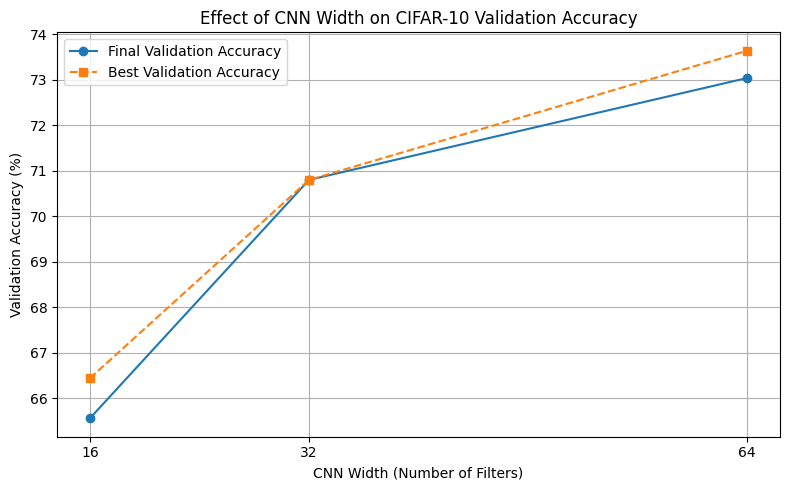

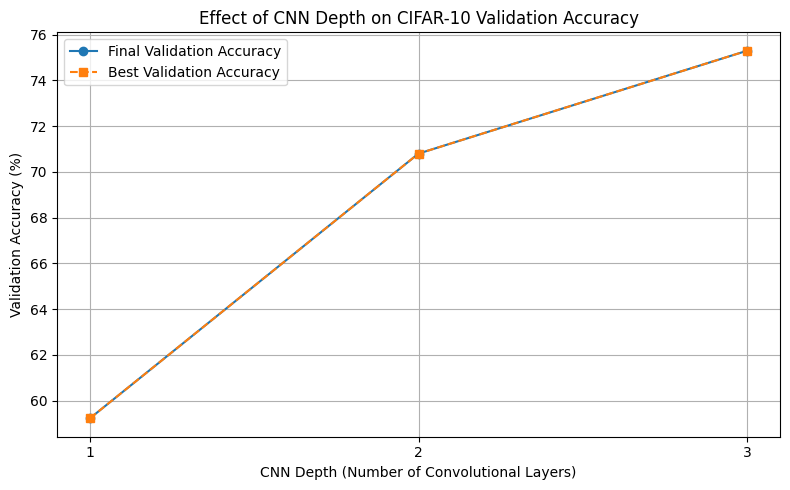

Both graphs saved to: /content/mydrive/MyDrive/PUSL3123_Exercise4_Final


In [19]:
import matplotlib.pyplot as plt

# -------------------------
# Width comparison
# -------------------------
width_data = results_df[results_df["Experiment"].isin(
    ["Narrow", "Medium", "Wide"]
)].sort_values("Width")

plt.figure(figsize=(8, 5))

plt.plot(
    width_data["Width"],
    width_data["Final Validation Accuracy (%)"],
    marker="o",
    label="Final Validation Accuracy"
)

plt.plot(
    width_data["Width"],
    width_data["Best Validation Accuracy (%)"],
    marker="s",
    linestyle="--",
    label="Best Validation Accuracy"
)

plt.xlabel("CNN Width (Number of Filters)")
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of CNN Width on CIFAR-10 Validation Accuracy")
plt.xticks(width_data["Width"])
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(results_folder, "width_comparison.png"),
    dpi=300
)

plt.show()


# -------------------------
# Depth comparison
# -------------------------
depth_data = results_df[results_df["Experiment"].isin(
    ["Shallow", "Medium", "Deep"]
)].sort_values("Depth")

plt.figure(figsize=(8, 5))

plt.plot(
    depth_data["Depth"],
    depth_data["Final Validation Accuracy (%)"],
    marker="o",
    label="Final Validation Accuracy"
)

plt.plot(
    depth_data["Depth"],
    depth_data["Best Validation Accuracy (%)"],
    marker="s",
    linestyle="--",
    label="Best Validation Accuracy"
)

plt.xlabel("CNN Depth (Number of Convolutional Layers)")
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of CNN Depth on CIFAR-10 Validation Accuracy")
plt.xticks(depth_data["Depth"])
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(results_folder, "depth_comparison.png"),
    dpi=300
)

plt.show()

print("Both graphs saved to:", results_folder)

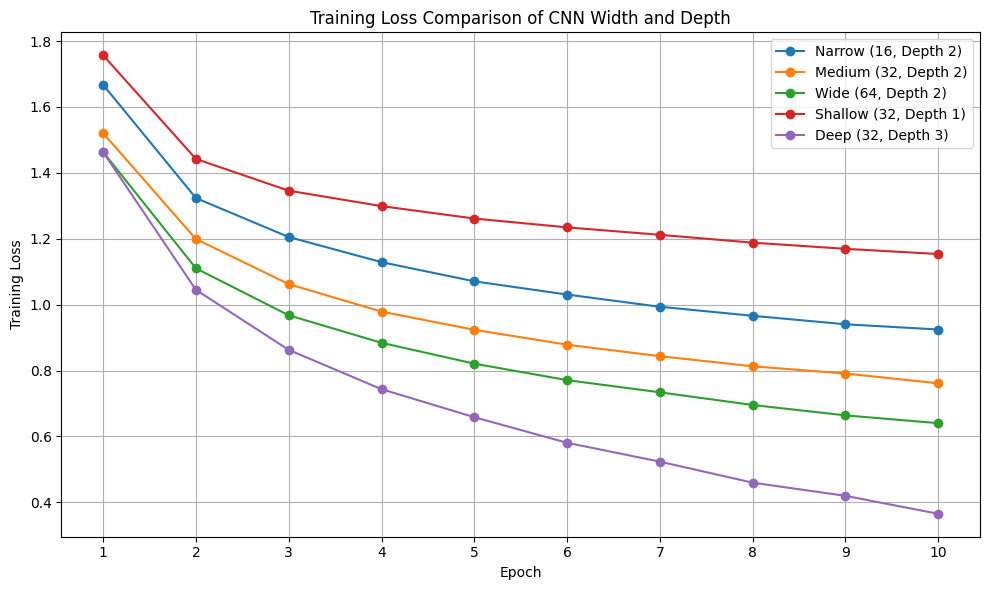

Training loss graph saved successfully.


In [20]:
plt.figure(figsize=(10, 6))

plt.plot(narrow_train_losses, marker="o", label="Narrow (16, Depth 2)")
plt.plot(medium_train_losses, marker="o", label="Medium (32, Depth 2)")
plt.plot(wide_train_losses, marker="o", label="Wide (64, Depth 2)")
plt.plot(shallow_train_losses, marker="o", label="Shallow (32, Depth 1)")
plt.plot(deep_train_losses, marker="o", label="Deep (32, Depth 3)")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison of CNN Width and Depth")
plt.xticks(range(10), range(1, 11))
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(results_folder, "training_loss_comparison.png"),
    dpi=300
)

plt.show()

print("Training loss graph saved successfully.")

### Discussion

The results show that increasing the width and depth of the CNN improved validation accuracy. In the width experiment, accuracy increased from 65.56% for the Narrow model to 73.04% for the Wide model. Increasing the number of filters helped the model learn more features from the images, but also increased the number of parameters.

In the depth experiment, the Shallow model achieved 59.22% accuracy, while the Deep model achieved 75.30%. This shows that adding more convolutional layers helped the model learn more complex image features.

The training loss decreased for all models throughout the training process. However, the larger models achieved higher training accuracy than validation accuracy, suggesting some potential overfitting. The Deep model achieved the highest validation accuracy, but it also had the highest number of parameters.

Overall, increasing CNN width and depth improved performance in this experiment, but it also increased model complexity and computational requirements. The Deep model provided the best validation performance among the tested architectures.
